<a href="https://colab.research.google.com/github/Marc0-dev/qiskit-fall-fest-2026-esercizi-svolti/blob/main/QFF_N1_svolto_Marco_Cunsolo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Quantum Computing e Qiskit in pillole**

*Prima di iniziare: esegui la seguenti celle di codice! In questo modo potrai utilizzare la libreria Qiskit, assieme ad una funzione che abbiamo creato appositamente per permettervi di testare velocemente i vostri circuiti!*

In [ ]:
%pip install qiskit qiskit_aer qiskit_ibm_runtime numpy pylatexenc

In [ ]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.executor_sampler import Sampler
from qiskit.visualization import plot_histogram
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
import numpy as np

In [ ]:
def run(qc, shots=1024):
    sim_backend = AerSimulator()
    pm = generate_preset_pass_manager(backend=sim_backend)
    isa_qc = pm.run(qc)
    sampler = Sampler(mode=sim_backend)

    job = sampler.run([isa_qc], shots=shots)
    results = job.result()
    counts = results[0].data.c.get_counts()
    return counts

## **Le prime porte logiche**

### Porta NOT (o X)

Questo gate **inverte completamente lo stato del qubit**. Ad esempio, da $\ket{0}$ a $\ket{1}$ e viceversa.

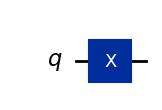

In [ ]:
qc = QuantumCircuit(1)
qc.x(0)
qc.draw('mpl')

### Porta Z

Questo gate **inverte il segno (la fase) dello stato**.

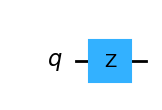

In [ ]:
qc = QuantumCircuit(1)
qc.z(0)
qc.draw('mpl')

### NOT controllato, CNOT (o CX)
Questo gate inverte lo stato del qubit target **solo se il qubit di controllo è 1**.

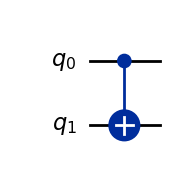

In [ ]:
qc = QuantumCircuit(2)
qc.cx(0,1)
qc.draw('mpl')

### SWAP

Questo gate **scambia gli stati dei due qubit** tra di loro.

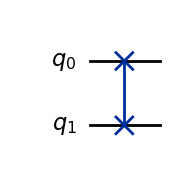

In [ ]:
qc = QuantumCircuit(2)
qc.swap(0,1)
qc.draw('mpl')

### Porta di Hadamard (o H)

Questo gate mette un qubit nello stato di **sovrapposizione quantistica**.

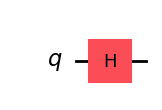

In [ ]:
qc = QuantumCircuit(1)
qc.h(0)
qc.draw('mpl')

### Porta di Toffoli (CNOT Controllato o CCNOT)

Questo gate usa **due qubit di controllo e un qubit target**. Se i due qubit di controllo collassano ad 1 allora inverte lo stato del qubit target.

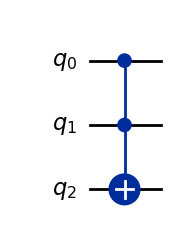

In [ ]:
qc = QuantumCircuit(3)
qc.ccx(0,1,2)
qc.draw('mpl')

### Misurazione

Operazione che fa collassare il qubit. Necessita di un bit classico come secondo argomento della funzione per memorizzare lo stato del qubit collassato.

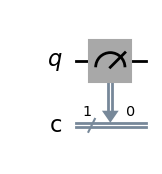

In [ ]:
qc = QuantumCircuit(1,1)
qc.measure(0,0)
qc.draw('mpl')

## Esercizio 1: **Quantum Coin**

Nulla, nel mondo dell'informatica classica, è veramente casuale. Sfruttiamo le proprietà della meccanica quantistica, usando il quantum computing come ponte, per creare una "moneta" totalmente casuale.

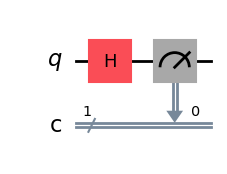

In [ ]:
qc = QuantumCircuit(1,1)
qc.h(0)
qc.measure(0, 0)
qc.draw('mpl')

Visualizziamo adesso i risultati! Utilizza la funzione definita a inizio file chiamata `run(qc: QuantumCircuit)` per eseguire il circuito, e la funzione `plot_histogram(counts: list)` per mostrare gli esiti.

{'1': 532, '0': 492}


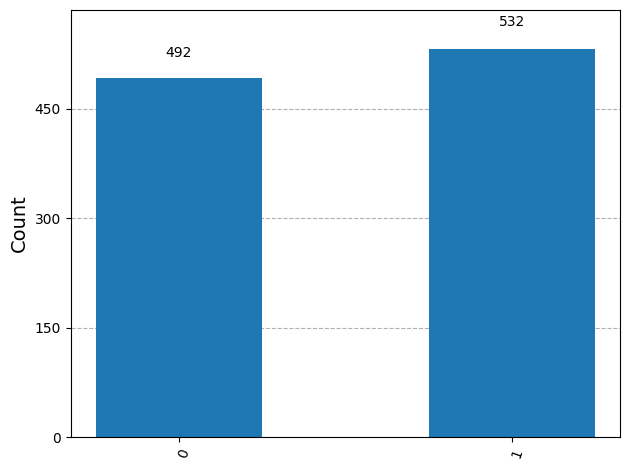

In [ ]:
counts = run(qc)
print(counts)
plot_histogram(counts)

## Esercizio 2: **Quantum Random Number**
Facciamo un altro esercizio! Creiamo una funzione che ritorni un circuito quantistico per generare un numero casuale a $n$ cifre.

In [ ]:
def rand_number_quantum_circuit(n=1):
    qc = QuantumCircuit(n,n)
    for i in range(n):
      qc.h(i)
      qc.measure(i,i)
    return qc

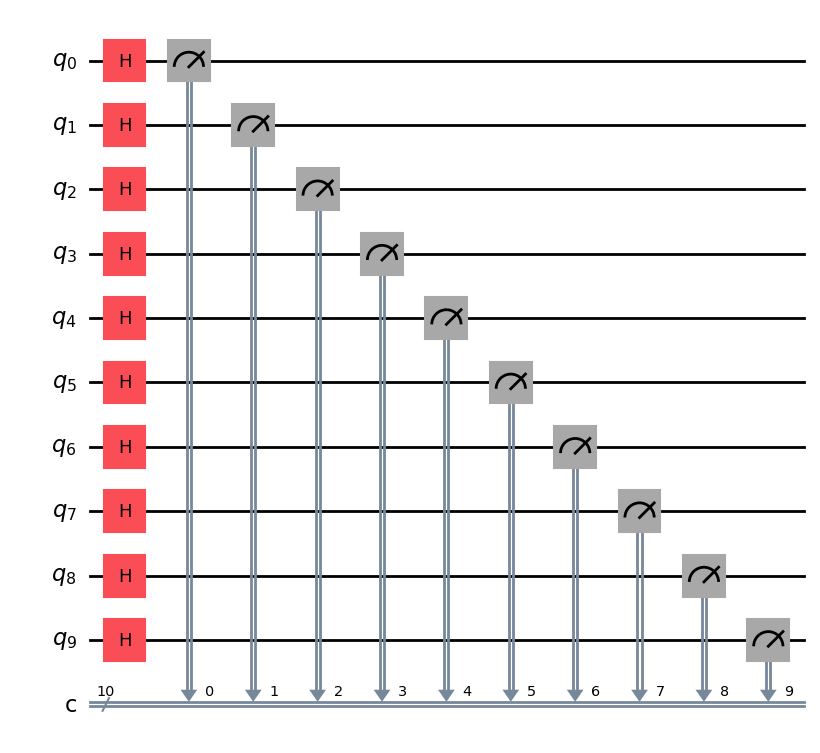

In [ ]:
qc = rand_number_quantum_circuit(10)
qc.draw('mpl')

Usa il seguente segmento di codice per convertire la codifica binaria del numero generato in un numero decimale.

In [ ]:
result = run(qc, 1)
result = list(list(result)[0])

# algoritmo di conversione da binario a decimale
num = 0
for pos, i in enumerate(result, start=0):
    num += int(i) * 2 ** pos
    pos += 1

print(num)

895


## **Come facciamo a rendere utile la casualità?** - *Algoritmo di Grover*

Il gioco di probabilità è sicuramente uno degli aspetti più affascinanti (o confusionari) della computazione quantistica. L'algoritmo di Grover è un esempio molto interessante di come, tramite un opportuno circuito, si possa manipolare la probabilità dei vari possibili stati misurabili, per ottenere i risultati desiderati.

### **Il problema della ricerca**
Trovare uno specifico elemento in un insieme di 10 scatole disordinate, significa dover aprire fino a 10 scatole. Con $n$ scatole, $n$ passi. Diremo l'algoritmo di **ricerca lineare** un problema $O(n)$.

L'algoritmo di Grover offre un approccio alternativo alla ricerca, proponendo un algoritmo con complessità $O(\sqrt{n})$.
Un problema di grandezza $n=4$ sarà risolto in $2$, e non $4$ passi. Un problema di grandezza $n=1000000$ sarà risolto solo in $1000$ passi, e non più $1000000$.


[0.5 0.5 0.5 0.5]


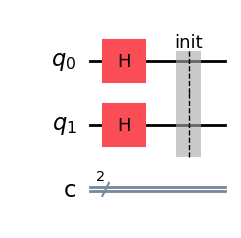

In [ ]:
# Inizializza un circuito con 2 qubit e 2 bit classici
qc = QuantumCircuit(2, 2)

# 1. Sovrapposizione: Hadamard su entrambi i qubit
qc.h(range(2))
qc.barrier(label='init')

state = Statevector.from_instruction(qc)
print(np.real(state))
qc.draw('mpl')

[ 0.5  0.5 -0.5  0.5]


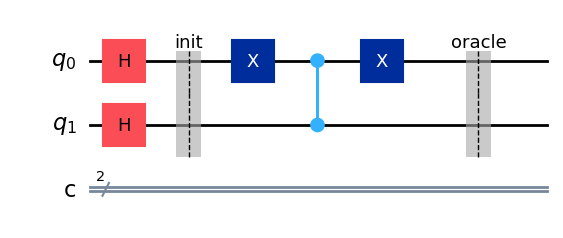

In [ ]:
# Inizializza un circuito con 2 qubit e 2 bit classici
qc = QuantumCircuit(2, 2)

# 1. Sovrapposizione: Hadamard su entrambi i qubit
qc.h(range(2))
qc.barrier(label='init')

# 2. Oracolo: cerchiamo lo stato |10⟩
qc.x(0)          # inverti bit 0 (LSB)
qc.cz(0, 1)      # CZ su bit 0 e 1
qc.x(0)          # reinverti bit 0, da commentare per ottenere 11
qc.barrier(label='oracle')

state = Statevector.from_instruction(qc)
print(np.real(state))
qc.draw('mpl')

[0. 0. 1. 0.]


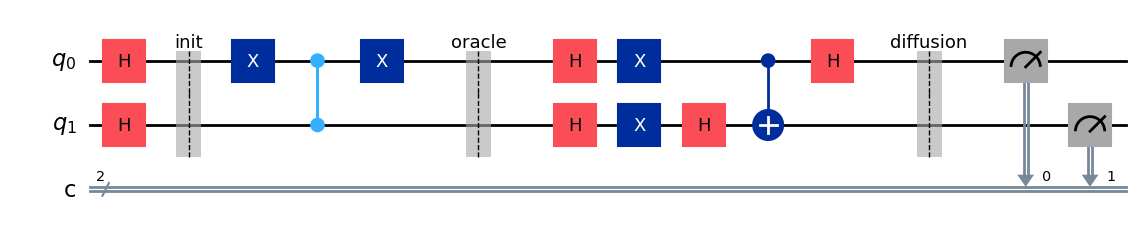

In [ ]:
# Inizializza un circuito con 2 qubit e 2 bit classici
qc = QuantumCircuit(2, 2)

# 1. Sovrapposizione: Hadamard su entrambi i qubit
qc.h(range(2))
qc.barrier(label='init')

# 2. Oracolo: cerchiamo lo stato |10⟩
qc.x(0)          # inverti bit 0 (LSB)
qc.cz(0, 1)      # CZ su bit 0 e 1
qc.x(0)          # reinverti bit 0, da commentare per ottenere 11
qc.barrier(label='oracle')

# 3. Diffusione (inversione rispetto alla media)
qc.h([0, 1])
qc.x([0, 1])
qc.h(1)
qc.cx(0, 1)
qc.h(0)
qc.barrier(label='diffusion')

state = Statevector.from_instruction(qc)
print(np.round(np.real(state)))

qc.measure([0, 1], [0, 1])
qc.draw('mpl')

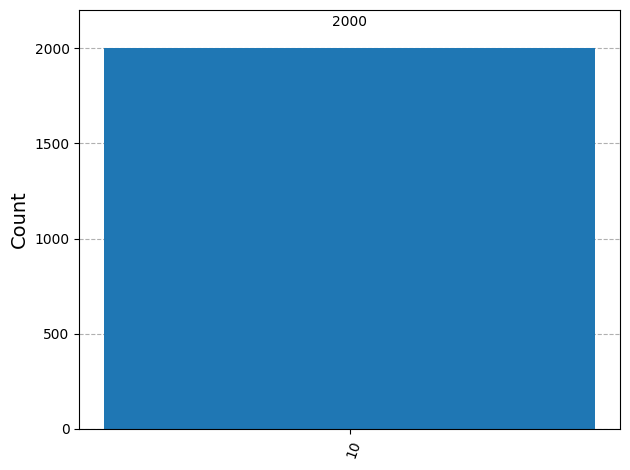

In [ ]:
counts = run(qc, 2000)
plot_histogram(counts)

## **Entanglement**

Facendo interagire in maniera opportuna due qubit (due particelle), è possibile metterli in una condizione di **correlazione**, meglio nota come ***entanglement***. Conoscere lo stato di una, significa conoscere lo stato dell'altra, perché queste sono correlate.

### **Entanglement simmetrico**

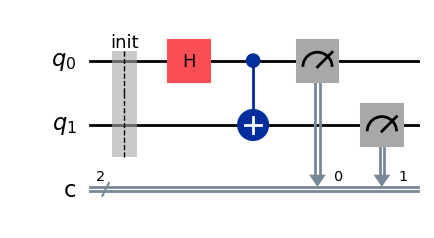

In [ ]:
qc = QuantumCircuit(2,2)

#inizializzazione stato
qc.barrier(label="init")

#entanglement
qc.h(0)
qc.cx(0,1)
qc.measure(range(2), range(2))
qc.draw('mpl')

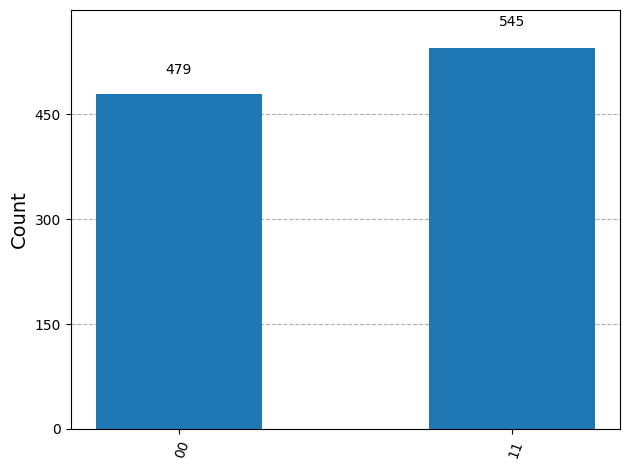

In [ ]:
counts = run(qc)
plot_histogram(counts)

### **Entanglement antisimmetrico**

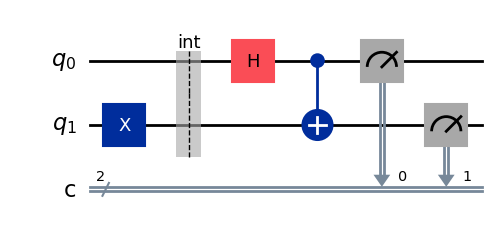

In [ ]:
qc = QuantumCircuit(2,2)

#inizializzare lo stato in 01
qc.x(1)
qc.barrier(label="int")

#entanglement
qc.h(0)
qc.cx(0,1)
qc.measure(range(2), range(2))
qc.draw('mpl')

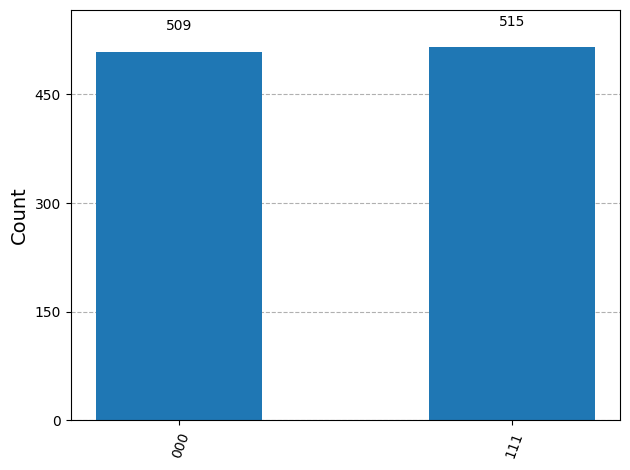

In [ ]:
counts = run(qc)
plot_histogram(counts)

## Esercizio 3: **Stati GHZ** - *Entanglement a più qubit!*

Crea un circuito quantistico che ritorni sempre $|000\rangle$ o $|111\rangle$.

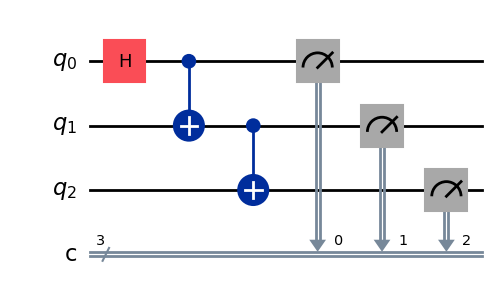

In [ ]:
qc = QuantumCircuit(3,3)
qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)
qc.measure(range(3),range(3))
qc.draw('mpl')

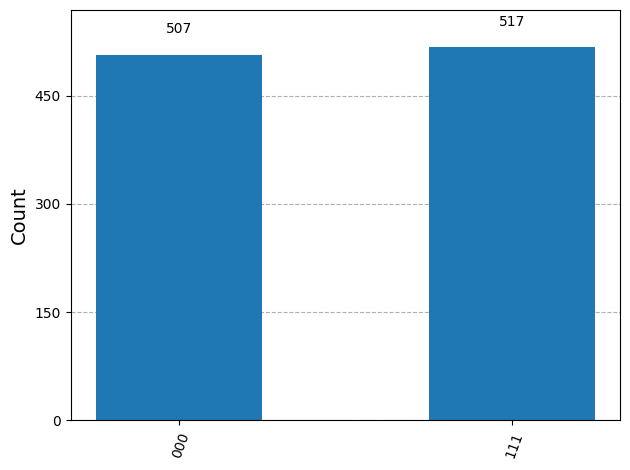

In [ ]:
# usa questa cella per verificare i risultati
counts = run(qc, 1024)
plot_histogram(counts)

### Esercizio 3.1:

Crea un circuito quantistico che ritorni sempre $|010\rangle$ o $|101\rangle$.

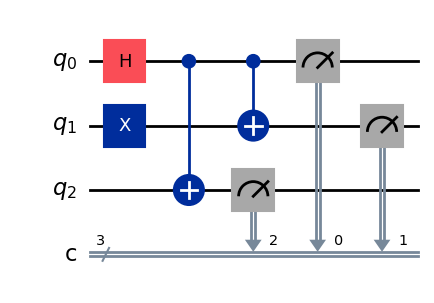

In [ ]:
qc = QuantumCircuit(3,3)
qc.x(1)
qc.h(0)
qc.cx(0, 2)
qc.cx(0, 1)
qc.measure(range(3),range(3))
qc.draw('mpl')

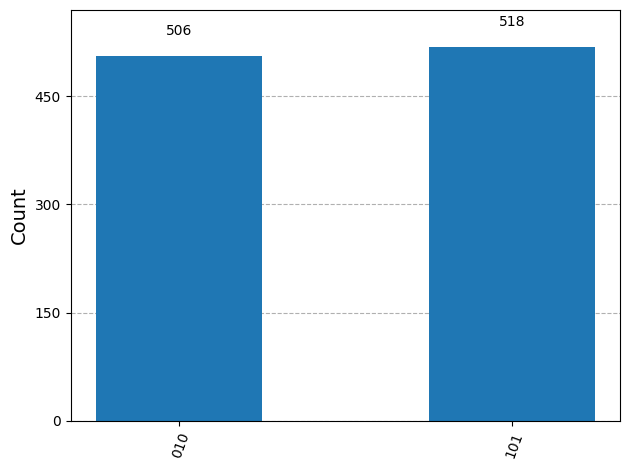

In [ ]:
# usa questa cella per verificare i risultati
counts = run(qc, 1024)
plot_histogram(counts)

### Esercizio 3.2:

Crea una funzione che genera un circuito quantistico che torna sempre $|00\dots 0\rangle$ o $|11\dots 1\rangle$.

In [ ]:
def generalized_ghz(n: int):
    qc = QuantumCircuit(n, n)
    qc.h(0)
    for i in range(1, n):
      qc.cx(0, i)
    qc.measure(range(n),range(n))
    return qc

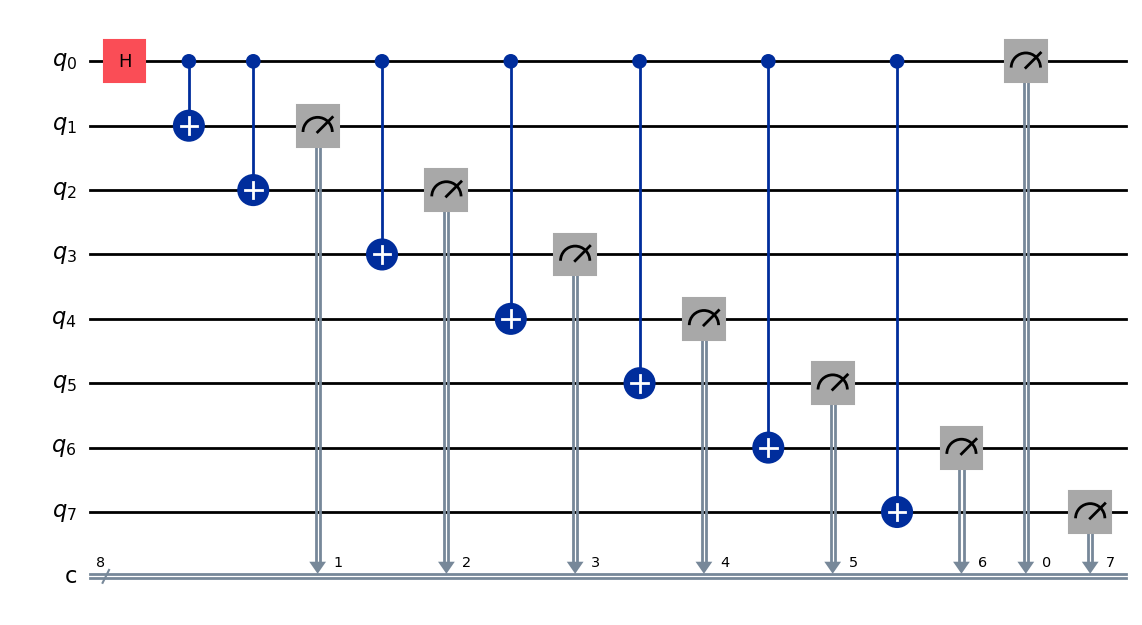

In [ ]:
qc = generalized_ghz(8)
qc.draw('mpl')

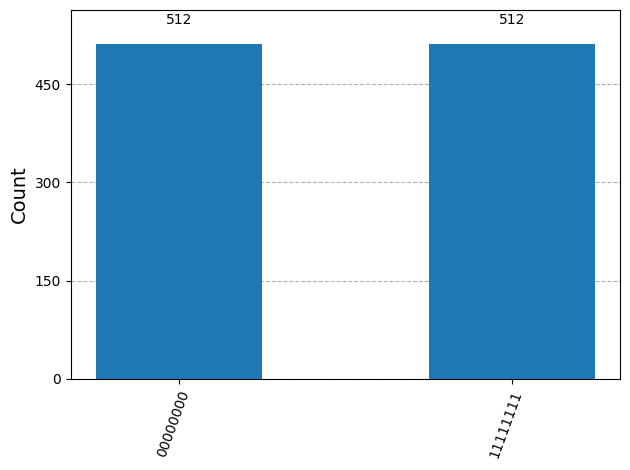

In [ ]:
counts = run(qc)
plot_histogram(counts)

## Esercizio 4: **Come sfruttiamo l'entanglement?** - *Superdense Coding*

Esiste un protocollo di comunicazione quantistica capace di codificare due bit di informazione in un singolo qubit di una coppia in entanglement.

> *Charlie fornisce ad Alice ($q_1$) e a Bob ($q_0$) una coppia di fotoni (qubit) in entanglement.*
>
> *Alice effettua delle trasformazioni esclusivamente sul proprio qubit, e lo manda a Bob.*
>
> *Bob riceve il qubit e lo legge assieme al proprio.*

Alice riesce a comunicare in maniera univoca una stringa di due bit, interagendo solo con uno dei qubit.

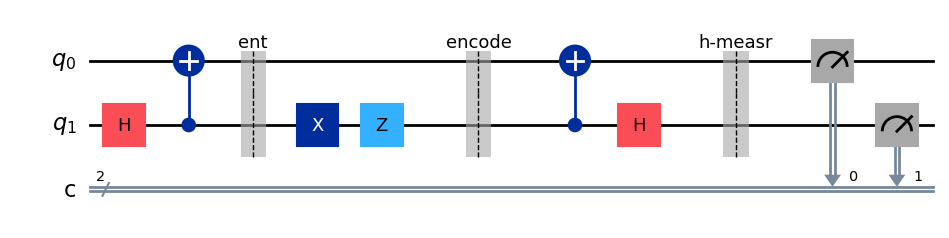

In [ ]:
qc = QuantumCircuit(2,2) #circuito con due qubit e due bit

bit_0 = 1 # bit da comunicare - bit meno significativo
bit_1 = 1 # bit da comunicare - bit più significativo

# entanglement (Charlie - il provider)

# crea l'entanglement simmetrico tra q_0 e q_1
qc.h(1)
qc.cx(1, 0)
qc.barrier(label="ent")

# codifica (Alice - il mittente)
if bit_0:
    # metti x su 1 (cancella pass)
    qc.x(1)
if bit_1:
    # metti z su 1 (cancella pass)
    qc.z(1)
qc.barrier(label="encode")

# decodifica (Bob - il destinatario)
# applica cnot su 0 con controllo su 1
qc.cx(1, 0)
# applica hadamard su 1
qc.h(1)
qc.barrier(label="h-measr")


qc.measure(range(2),range(2)) # decodifica
qc.draw('mpl')


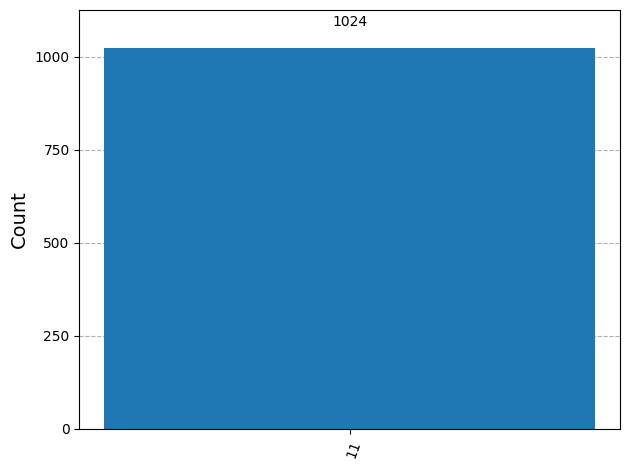

In [ ]:
counts = run(qc, 1024)
plot_histogram(counts)

# Esercizio 5: **Come sfruttiamo l'entanglement?** - *Quantum Teleportation*

Un altro protocollo di comunicazione quantistica che sfrutta l'entanglement è il Quantum Teleportation!

> *Charlie fornisce ad Alice e Bob una coppia di qubit ($q_1$ e $q_2$) in entanglement*
>
> *Alice applica delle trasformazioni coivolgendo il suo qubit e quello da trasferire*
>
> *Alice misura i qubit $q_0$ e $q_1$ sui bit classici*
>
> *Bob effettua delle correzioni al suo qubit tenendo in considerazione i bit classici ricevuti da Alice*
>
> *Infine Bob misura il suo qubit $q_2$ sul primo bit classico e ricostruisce il qubit $q_0$*.

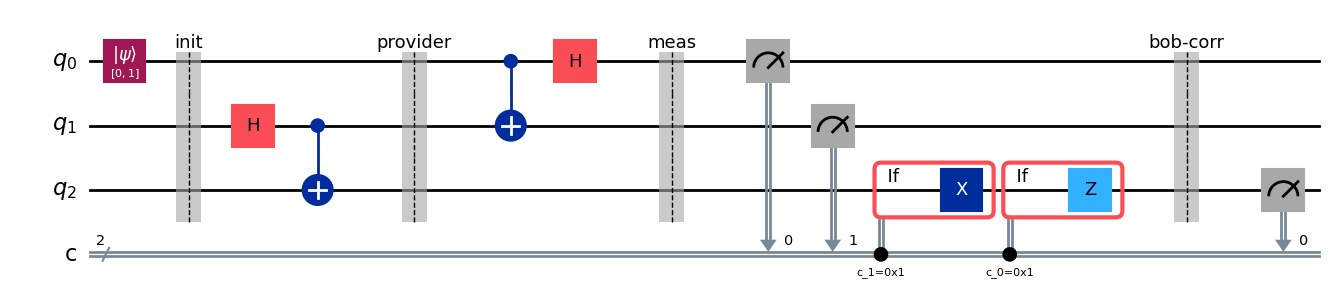

In [ ]:
qc = QuantumCircuit(3,2) #circuito con 3 qubit e 2 bit classici

# stato da teletrasportare
state = [np.cos(np.pi/2), np.sin(np.pi/2)]
qc.initialize(state, 0)
qc.barrier(label="init")

# entanglement (Charlie - il provider)
# crea la coppia di qubit in entaglement
qc.h(1)
qc.cx(1,2)
qc.barrier(label="provider")

# codifica (Alice - il sender)
qc.cx(0, 1)
qc.h(0)
qc.barrier(label="meas")

# misura dei qubit da parte di Alice sui bit classici
qc.measure(0,0)
qc.measure(1,1)

# decodifica e correzione (Bob - il receiver)
#se il bit 1 è 1 applica X su q_2
with qc.if_test((qc.clbits[1], 1)):
    qc.x(2)
#se il bit 0 è 1 applica Z su q_2
with qc.if_test((qc.clbits[0], 1)):
    qc.z(2)

qc.barrier(label="bob-corr")

#misura il qubit di Bob sul bit 0
qc.measure(2,0)

qc.draw('mpl')


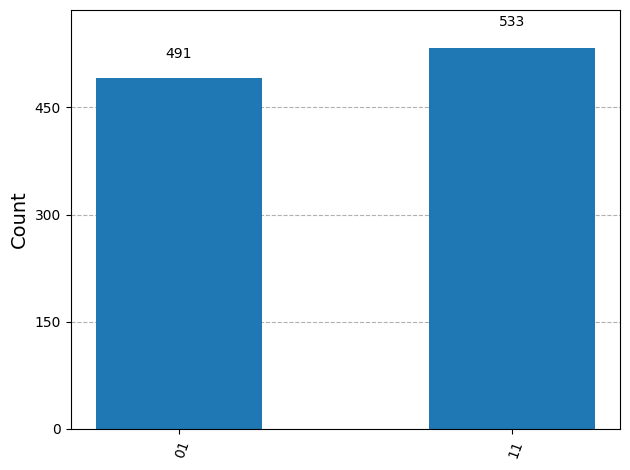

In [ ]:
counts = run(qc, 1024)
plot_histogram(counts)

## Esercizio 6: **Sperimentiamo!**

Usa questa cella di codice per sperimentare con Qiskit, e crea qualche circuito seguendo gli esercizi svolti in precedenza!

In [ ]:
qc = QuantumCircuit(3, 3)

# Porta tutti e 3 i qubit in sovrapposizione
qc.h([0, 1, 2])

# Misura tutti i qubit
qc.measure([0, 1, 2], [0, 1, 2])

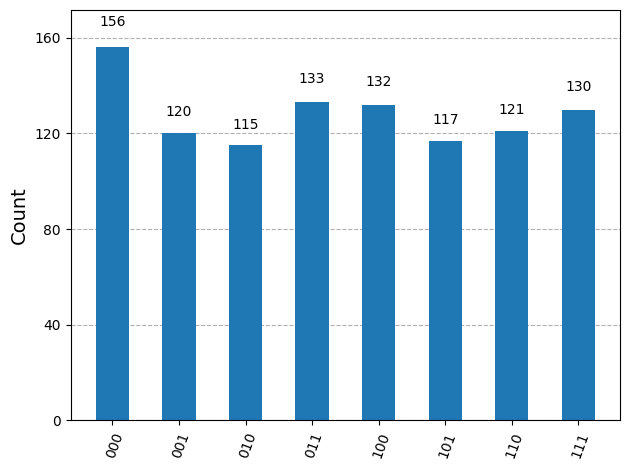

In [ ]:
counts = run(qc, 1024)
plot_histogram(counts)